# 垃圾分類 RAG｜RAG01：建立向量資料庫

**B1243006 資工四 周俊丞**｜第七週作業：打造自己的 RAG 對話機器人

這支程式讀取我準備的**垃圾分類資料（18 篇 TXT）**，用 EmbeddingGemma 2 把每篇文件轉成向量，建立 FAISS 向量資料庫，最後打包成 **`vector_embedding.zip`**，交給 RAG02 的「清潔隊大哥」對話機器人使用。

| 項目 | 內容 |
|---|---|
| 文字資料 | 18 篇垃圾分類 TXT，一篇一個主題（手搖飲料杯、便當盒、電池、廚餘、罰則……），打包成 `rag-data.zip` 放在 GitHub：[b1243006/garbage-rag](https://github.com/b1243006/garbage-rag)（`rag-data/` 資料夾可直接瀏覽每篇 TXT） |
| 資料來源 | 環境部〈一般廢棄物回收項目排出方式〉、環境部回收百科、桃園市政府環境管理處、全國法規資料庫（廢棄物清理法）與新聞報導；以生成式 AI 協助整理成摘要，不是官方原文 |
| Embedding 模型 | `google/embeddinggemma-2`（一篇文件一個向量，不切塊） |
| 向量資料庫 | FAISS `IndexFlatIP`：向量正規化後，內積就是 cosine similarity |
| 輸出 | `vector_embedding.zip`（`index.faiss`、`documents.json`、`config.json`） |

**執行方式**：「執行階段 → 變更執行階段類型」選 GPU（T4 即可），再「全部執行」。資料會自動從 GitHub 下載，不需要上傳檔案，也不需要 API 金鑰。

## 1. 安裝套件

In [1]:
%pip install -q "sentence-transformers==6.1.0" "transformers==5.20.1" "faiss-cpu==1.15.1"

## 2. 匯入套件

In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
import io
import json
import re
import hashlib
import tempfile
import zipfile
import urllib.request
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import torch
import faiss
from sentence_transformers import SentenceTransformer
from huggingface_hub import HfApi
from IPython.display import display

## 3. 設定

- `TEXT_DATA_URL`：文字資料 `rag-data.zip` 的網址。這個網址固定在 GitHub 的某一次 commit，之後 repo 更新，下載到的仍是同一份 18 篇 TXT。
- `OUTPUT_ZIP`：向量資料庫打包成 `vector_embedding.zip`，給 RAG02 讀取。
- EmbeddingGemma 會用不同前綴區分「文件」和「問題」，所以文件和問題各有一個樣板。

In [4]:
TEXT_DATA_URL = "https://github.com/b1243006/garbage-rag/blob/7a572f4902a3bf8659102640b00ca54547a6773d/rag-data.zip"
OUTPUT_ZIP = "vector_embedding.zip"

MODEL_ID = "google/embeddinggemma-2"
DOCUMENT_TEMPLATE = "title: none | text: {text}"            # 文件前綴（標題已經寫在 text 裡）
QUERY_TEMPLATE = "task: search result | query: {question}"  # 問題前綴
TOKEN_LIMIT = 2048
BATCH_SIZE = 4

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16 if DEVICE == "cuda" and torch.cuda.is_bf16_supported() else torch.float32  # T4 不支援 bfloat16，會用 float32
print("裝置：", DEVICE, "／精度：", DTYPE)

裝置： cuda ／精度： torch.bfloat16


## 4. 從網址下載並解壓縮文字資料

GitHub 檔案頁面的網址（含 `/blob/`）打開是網頁，不是檔案，要換成 `/raw/` 才會直接下載；Google 雲端硬碟的分享連結也要轉成下載格式。`to_download_url()` 會自動轉換，助教執行時不用手動上傳。

解壓縮時只讀 `.txt`，而且直接讀進記憶體，不寫到硬碟。

In [5]:
def to_download_url(url):
    """把 GitHub 檔案頁面或 Google 雲端硬碟分享連結，轉成可以直接下載的網址。"""
    if "github.com" in url and "/blob/" in url:
        return url.replace("/blob/", "/raw/", 1)
    match = re.search(r"drive\.google\.com/(?:file/d/|open\?id=)([\w-]+)", url)
    if match:
        return f"https://drive.google.com/uc?export=download&id={match.group(1)}"
    return url


def download_zip(url):
    download_url = to_download_url(url)
    with urllib.request.urlopen(download_url, timeout=60) as response:
        data = response.read()
    if not zipfile.is_zipfile(io.BytesIO(data)):
        raise ValueError(f"下載到的不是 zip 檔，請檢查網址：{download_url}")
    return data


text_zip_bytes = download_zip(TEXT_DATA_URL)
with zipfile.ZipFile(io.BytesIO(text_zip_bytes)) as archive:
    raw_texts = {
        Path(name).name: archive.read(name).decode("utf-8-sig")
        for name in sorted(archive.namelist())
        if name.lower().endswith(".txt") and not name.startswith("__MACOSX")
    }

print(f"下載 {len(text_zip_bytes):,} bytes，共 {len(raw_texts)} 篇 TXT：")
for name in raw_texts:
    print("•", name)

下載 17,603 bytes，共 18 篇 TXT：
• 01_手搖飲料杯.txt
• 02_便當盒與免洗餐具.txt
• 03_紙類回收.txt
• 04_鋁箔包與紙盒包.txt
• 05_寶特瓶與塑膠容器.txt
• 06_塑膠袋與不可回收塑膠.txt
• 07_保麗龍.txt
• 08_鐵鋁罐與高壓罐.txt
• 09_玻璃陶瓷與碎玻璃.txt
• 10_乾電池與行動電源.txt
• 11_燈管與水銀溫度計.txt
• 12_廚餘分類.txt
• 13_廢食用油.txt
• 14_舊衣回收.txt
• 15_手機與家電.txt
• 16_巨大垃圾.txt
• 17_丟錯的罰則.txt
• 18_各地規定與查詢.txt


## 5. 解析 TXT：正文與 metadata

每篇 TXT 的格式：

```
標題：手搖飲料杯怎麼丟
分類：資源回收
資料類型／資料來源單位／來源網址／補充來源／資料整理日期
【內容】          ← 送進 embedding，也是之後交給 LLM 的參考資料
【檢索練習問題】  ← 不送進 embedding，只用來測試檢索
【提醒】
```

- **text**：標題＋【內容】，是真正被向量化的文字。
- **metadata**：分類、來源單位、網址、日期，用來在 RAG02 顯示來源，不會送進 embedding。
- **檢索練習問題**如果也送進 embedding，搜尋時會直接命中題目本身，就看不出正文寫得好不好，所以分開存。

In [6]:
FIELD_KEYS = {
    "標題": "title",
    "分類": "category",
    "資料類型": "document_type",
    "資料來源單位": "source_org",
    "來源網址": "source_url",
    "補充來源": "extra_urls",
    "資料整理日期": "date",
}


def read_section(text, name):
    """讀出【name】到下一個【……】之間的文字。"""
    match = re.search(rf"^【{name}】[ \t]*\n(.*?)(?=^【[^】\n]+】|\Z)", text, flags=re.M | re.S)
    return match.group(1).strip() if match else ""


def parse_document(raw_text, filename):
    text = raw_text.replace("\r\n", "\n")
    header = text.split("【", 1)[0]
    fields = {k.strip(): v.strip() for k, v in re.findall(r"^([^：:\n]+)[：:](.*)$", header, flags=re.M)}

    metadata = {key: fields.get(zh) or None for zh, key in FIELD_KEYS.items()}
    metadata["title"] = metadata["title"] or Path(filename).stem
    extra = metadata["extra_urls"]
    metadata["extra_urls"] = [u.strip() for u in extra.split("；") if u.strip()] if extra and extra != "無" else []
    metadata["filename"] = filename

    body = read_section(text, "內容")
    if not body:
        raise ValueError(f"{filename} 找不到【內容】")
    questions = [q.strip() for q in read_section(text, "檢索練習問題").splitlines() if q.strip()]
    return {"text": f"{metadata['title']}\n\n{body}", "metadata": metadata, "practice_questions": questions}


documents = [
    {"doc_id": f"doc_{number:02d}", **parse_document(raw, filename)}
    for number, (filename, raw) in enumerate(raw_texts.items(), start=1)
]

display(pd.DataFrame([
    {"doc_id": d["doc_id"], "標題": d["metadata"]["title"], "分類": d["metadata"]["category"],
     "正文字數": len(d["text"]), "練習問題": len(d["practice_questions"])}
    for d in documents
]))
print("各分類篇數：")
print(pd.Series([d["metadata"]["category"] for d in documents]).value_counts().to_string())
print("\n第一篇送進 embedding 的文字：\n")
print(documents[0]["text"])

,doc_id,標題,分類,正文字數,練習問題
0,doc_01,手搖飲料杯怎麼丟,資源回收,243,2
1,doc_02,便當盒、紙餐具與免洗餐具,資源回收,166,1
2,doc_03,紙類回收：哪些可以、哪些不行,資源回收／一般垃圾,216,2
3,doc_04,鋁箔包與紙盒包,資源回收,113,1
4,doc_05,寶特瓶與塑膠容器,資源回收,151,2
5,doc_06,塑膠袋、零食袋與不能回收的塑膠,資源回收／一般垃圾,222,2
6,doc_07,保麗龍怎麼回收,資源回收,116,1
7,doc_08,鐵罐、鋁罐與高壓罐,資源回收（高壓罐需特別處理）,207,1
8,doc_09,玻璃、陶瓷與碎玻璃,資源回收／一般垃圾,209,1
9,doc_10,乾電池與行動電源,特殊回收（不可丟一般垃圾）,204,1


各分類篇數：
資源回收              6
資源回收／一般垃圾         3
特殊回收              2
資源回收（高壓罐需特別處理）    1
特殊回收（不可丟一般垃圾）     1
廚餘                1
資源回收（依縣市公告）       1
巨大垃圾              1
法規                1
法規與查詢             1

第一篇送進 embedding 的文字：

手搖飲料杯怎麼丟

手搖飲料杯可以回收，但要先拆解、清洗。桃園市政府環境管理處整理的四個步驟是：一、拔掉吸管，吸管丟一般垃圾；二、撕掉杯口的塑膠封膜，封膜丟一般垃圾；三、倒空杯中剩下的飲料，用清水簡單沖洗；四、把乾淨的杯子交給資源回收。
杯中剩下的珍珠等配料屬於食物殘渣，應依所在地清潔隊的廚餘規定處理，不要留在杯子裡。多數手搖飲紙杯是「淋膜紙杯」，屬於複合材質，要和一般紙類分開交給資源回收車；塑膠杯則屬於塑膠容器。塑膠杯蓋可以依塑膠容器回收，沒有沾到油汙的隔熱紙套可以放進紙類回收。


## 6. 載入 EmbeddingGemma 2

先查出模型目前的確切版本（commit），存進 `config.json`，RAG02 會載入同一個版本，確保「文件向量」和「問題向量」是同一個模型算出來的。這個模型有圖片、聲音的部分，這裡只啟用文字。

In [7]:
MODEL_REVISION = HfApi().model_info(MODEL_ID, token=False).sha
model = SentenceTransformer(
    MODEL_ID,
    revision=MODEL_REVISION,
    token=False,
    device=DEVICE,
    config_kwargs={"vision_config": None, "audio_config": None},
    model_kwargs={"dtype": DTYPE, "attn_implementation": "eager"},
)
print("模型：", MODEL_ID)
print("版本：", MODEL_REVISION)

modules.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/1.56k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/22.2k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/747 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.46k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.49GB            

... (7 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/90.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/97.0 [00:00<?, ?B/s]

模型： google/embeddinggemma-2
版本： f9972ac22e696a105c482202646979e33e4b5a1e


## 7. 文件向量化

先確認每篇加上前綴後都沒有超過 token 上限（我的文件都很短，不需要切塊），再把 18 篇轉成向量。向量正規化成長度 1，之後內積就等於 cosine similarity。

In [8]:
document_inputs = [DOCUMENT_TEMPLATE.format(text=d["text"]) for d in documents]
token_counts = [len(model.tokenizer(t, add_special_tokens=True, truncation=False)["input_ids"]) for t in document_inputs]
print("每篇 token 數：最少", min(token_counts), "／最多", max(token_counts))
if max(token_counts) > TOKEN_LIMIT:
    raise ValueError("有文件超過 token 上限，需要切塊。")

embeddings = model.encode(
    document_inputs,
    prompt="",                    # 前綴已經自己加了
    batch_size=BATCH_SIZE,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True,
)
embeddings = np.ascontiguousarray(embeddings, dtype=np.float32)
faiss.normalize_L2(embeddings)
DIMENSION = int(embeddings.shape[1])
print("向量矩陣：", embeddings.shape, "（文件數, 維度）")
print("前 3 篇向量長度：", np.linalg.norm(embeddings[:3], axis=1))

每篇 token 數：最少 81 ／最多 238


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

向量矩陣： (18, 768) （文件數, 維度）
前 3 篇向量長度： [1.        1.0000001 1.0000001]


## 8. 建立 FAISS 向量資料庫

`IndexFlatIP` 會把問題向量和每一篇文件向量都比一次（精確搜尋）。FAISS 只記得向量的順序編號，所以 `documents` 的順序要和向量一致，才能從編號找回原文。

In [9]:
index = faiss.IndexFlatIP(DIMENSION)
index.add(embeddings)
assert index.ntotal == len(documents)
print("索引向量數：", index.ntotal, "／維度：", index.d)

索引向量數： 18 ／維度： 768


## 9. 測試檢索

問題也要用同一個模型、加上問題前綴轉成向量，再到 FAISS 找最相近的文件。

第三題「宜蘭市的垃圾車幾點來？」資料裡**沒有答案**，但 FAISS 一樣會回傳最相近的文件：**相似度只代表「比較像」，不代表答得出來**。這部分要靠 RAG02 的 Prompt 讓模型在資料不足時老實說不知道。

In [10]:
def search(question, top_k=3):
    query = QUERY_TEMPLATE.format(question=question.strip())
    vector = model.encode([query], prompt="", convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False)
    vector = np.ascontiguousarray(vector, dtype=np.float32)
    faiss.normalize_L2(vector)
    scores, positions = index.search(vector, min(top_k, index.ntotal))
    return [(documents[int(p)], float(s)) for p, s in zip(positions[0], scores[0])]


for question in ["喝完的珍奶要怎麼丟？", "行動電源壞了可以丟垃圾桶嗎？", "宜蘭市的垃圾車幾點來？"]:
    print("\n問題：", question)
    display(pd.DataFrame([
        {"排名": rank, "doc_id": d["doc_id"], "標題": d["metadata"]["title"], "分類": d["metadata"]["category"], "相似度": round(s, 4)}
        for rank, (d, s) in enumerate(search(question), start=1)
    ]))


問題： 喝完的珍奶要怎麼丟？


,排名,doc_id,標題,分類,相似度
0,1,doc_01,手搖飲料杯怎麼丟,資源回收,0.7710
1,2,doc_04,鋁箔包與紙盒包,資源回收,0.7514
2,3,doc_08,鐵罐、鋁罐與高壓罐,資源回收（高壓罐需特別處理）,0.7074



問題： 行動電源壞了可以丟垃圾桶嗎？


,排名,doc_id,標題,分類,相似度
0,1,doc_10,乾電池與行動電源,特殊回收（不可丟一般垃圾）,0.7755
1,2,doc_16,巨大垃圾：家具與床墊,巨大垃圾,0.7296
2,3,doc_15,手機與家電回收,資源回收,0.7161



問題： 宜蘭市的垃圾車幾點來？


,排名,doc_id,標題,分類,相似度
0,1,doc_18,各縣市規定不同時怎麼查,法規與查詢,0.7136
1,2,doc_16,巨大垃圾：家具與床墊,巨大垃圾,0.6909
2,3,doc_12,廚餘：熟廚餘與生廚餘,廚餘,0.6713


執行結果

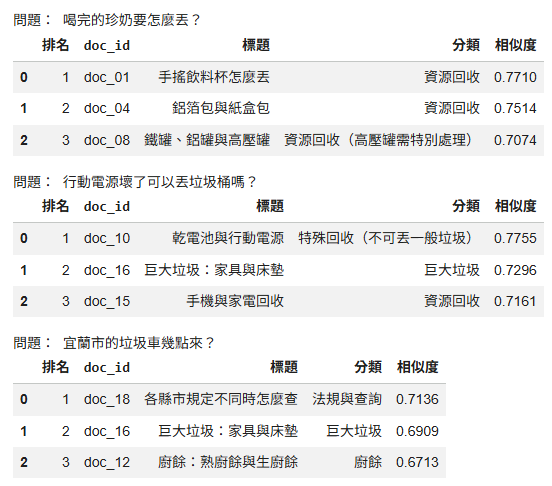

### 用練習問題檢查檢索命中率

每篇 TXT 都有「檢索練習問題」，而且沒有送進 embedding。拿這些問題去搜尋，看正確的那篇有沒有排在第 1 名、或至少在前 3 名，可以客觀檢查這份資料和 embedding 的檢索效果。

In [11]:
rows = []
for doc in documents:
    for question in doc["practice_questions"]:
        top_ids = [d["doc_id"] for d, _ in search(question, 3)]
        rows.append({
            "練習問題": question,
            "應該找到": doc["metadata"]["title"],
            "第 1 名命中": top_ids[0] == doc["doc_id"],
            "前 3 名命中": doc["doc_id"] in top_ids,
        })
hit_table = pd.DataFrame(rows)
display(hit_table)
print(f"共 {len(hit_table)} 題｜第 1 名命中率 {hit_table['第 1 名命中'].mean():.0%}｜前 3 名命中率 {hit_table['前 3 名命中'].mean():.0%}")

,練習問題,應該找到,第 1 名命中,前 3 名命中
0,喝完的珍奶要怎麼丟？,手搖飲料杯怎麼丟,True,True
1,杯子上的封膜可以回收嗎？,手搖飲料杯怎麼丟,True,True
2,便當紙盒要洗乾淨才能回收嗎？,便當盒、紙餐具與免洗餐具,True,True
3,電子發票可以丟紙類回收嗎？,紙類回收：哪些可以、哪些不行,True,True
4,衛生紙捲筒可以回收嗎？,紙類回收：哪些可以、哪些不行,True,True
5,喝完的鋁箔包可以拿去便利商店回收嗎？,鋁箔包與紙盒包,True,True
6,寶特瓶要壓扁嗎？,寶特瓶與塑膠容器,True,True
7,瓶蓋要拆下來嗎？,寶特瓶與塑膠容器,True,True
8,洋芋片的袋子可以回收嗎？,塑膠袋、零食袋與不能回收的塑膠,True,True
9,吸管可以回收嗎？,塑膠袋、零食袋與不能回收的塑膠,False,False


共 23 題｜第 1 名命中率 96%｜前 3 名命中率 96%


執行時間
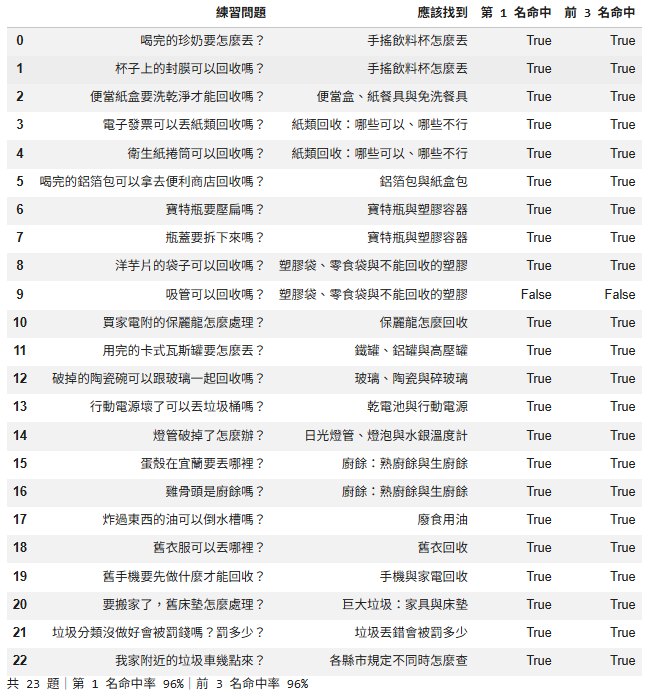

## 10. 儲存並打包成 vector_embedding.zip

| 檔案 | 用途 |
|---|---|
| `index.faiss` | 18 個文件向量和搜尋索引 |
| `documents.json` | 每篇的正文和 metadata，順序和向量一致；RAG02 找到編號後從這裡拿原文給 LLM |
| `config.json` | 模型名稱與確切版本、前綴樣板、維度、篇數、檔案雜湊值 |

模型本身不放進 zip（太大），RAG02 會依 `config.json` 重新下載同一個版本，只用來把新問題轉成向量。

In [12]:
export_dir = Path(tempfile.mkdtemp(prefix="rag_export_"))
faiss.write_index(index, str(export_dir / "index.faiss"))
(export_dir / "documents.json").write_text(json.dumps(documents, ensure_ascii=False, indent=2), encoding="utf-8")

config = {
    "created_at": datetime.now(ZoneInfo("Asia/Taipei")).isoformat(timespec="seconds"),
    "text_data_url": TEXT_DATA_URL,
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "model_config_kwargs": {"vision_config": None, "audio_config": None},
    "document_template": DOCUMENT_TEMPLATE,
    "query_template": QUERY_TEMPLATE,
    "token_limit": TOKEN_LIMIT,
    "dimension": DIMENSION,
    "document_count": len(documents),
    "index_type": "IndexFlatIP",
    "normalize_embeddings": True,
    "file_sha256": {
        name: hashlib.sha256((export_dir / name).read_bytes()).hexdigest()
        for name in ["index.faiss", "documents.json"]
    },
}
(export_dir / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

with zipfile.ZipFile(OUTPUT_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for name in ["index.faiss", "documents.json", "config.json"]:
        archive.write(export_dir / name, arcname=name)
print(f"已建立 {OUTPUT_ZIP}（{Path(OUTPUT_ZIP).stat().st_size:,} bytes）")

已建立 vector_embedding.zip（41,647 bytes）


### 重新載入檢查

從剛做好的 `vector_embedding.zip` 重新讀出索引和文件，用同一個問題搜尋，確認結果和打包前一樣，避免把壞掉的檔案交給 RAG02。

In [13]:
check_dir = Path(tempfile.mkdtemp(prefix="rag_check_"))
with zipfile.ZipFile(OUTPUT_ZIP) as archive:
    archive.extractall(check_dir)
reloaded_index = faiss.read_index(str(check_dir / "index.faiss"))
reloaded_docs = json.loads((check_dir / "documents.json").read_text(encoding="utf-8"))
assert reloaded_index.ntotal == len(reloaded_docs) == len(documents)
assert [d["doc_id"] for d in reloaded_docs] == [d["doc_id"] for d in documents]

query = QUERY_TEMPLATE.format(question="電子發票可以丟紙類回收嗎？")
vector = np.ascontiguousarray(model.encode([query], prompt="", convert_to_numpy=True, normalize_embeddings=True), dtype=np.float32)
faiss.normalize_L2(vector)
assert (reloaded_index.search(vector, 3)[1] == index.search(vector, 3)[1]).all()
print("檢查通過：vector_embedding.zip 內容完整，重新載入後搜尋結果相同。")

檢查通過：vector_embedding.zip 內容完整，重新載入後搜尋結果相同。


## 11. 下載 vector_embedding.zip

In [14]:
from google.colab import files
files.download(OUTPUT_ZIP)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**下一步**：把下載的 `vector_embedding.zip` 上傳到 GitHub repo 的根目錄（和 `rag-data.zip` 放在一起），RAG02 會從網址讀取。